**Group information**

| Family name | First name | Email address |
| ----------- | ---------- | ------------- |
|             |            |               |
|             |            |               |
|             |            |               |

# Collection - Solutions

This tutorial is a brief introduction to collecting and processing text data from the internet (web scraping), extracting structured information from HTML pages, and performing basic language analysis, using an application in media economics and sentiment analysis.

**Web scrapping** is the automated extraction of data from websites. It requires understanding web page structure (e.g. HTML, CSS, JavaScript), HTTP requests, and client–server interactions. Responsible scraping involves respecting rate limits and handling dynamically generated content.

**Some definitions:**

- **HTML (HyperText Markup Language)** is the standard markup language for structuring content on the web. Browsers read HTML and render it into the visual pages you see. 
- **CSS (Cascading Style Sheets)** is the style sheet language used to control the appearance and layout of HTML elements on a web page e.g. fonts, colours.
- **JavaScript** is the programming language that adds behaviour and interactivity to a web page, dynamically modifying content e.g. dropdown, buttons.

Note: **Large language models** can be powerful learning tools, but make sure to continue asking questions until you fully understand the produced answer and can judge its correctness. Simply copy-pasting generated code does not contribute to learning and is a waste of your class time.

In [13]:
# Google Colab users
# !pip install wordcloud

In [14]:
# Packages
import bs4
import datetime
import io
import matplotlib.pyplot as plt
import nltk
import numpy as np
import os
import pandas as pd
import random
import re
import requests
import shutil
import time
import urllib
import wordcloud

from nltk import sentiment
from nltk.util import ngrams
from PIL import Image
from pprint import pprint
from tqdm import tqdm
tqdm.pandas()

# NLTK downloads
nltk.data.path.clear()
nltk.data.path.append(os.path.expanduser('~/Software/nltk_data'))
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)
nltk.download('vader_lexicon', quiet=True)

True

In [ ]:
# Utilities
def download_data() -> None:
    if os.getcwd().endswith('/data'):
        print('Data folder already exists')
    else:
        urllib.request.urlretrieve('https://www.dropbox.com/scl/fo/i0j89n7gjnlyg7omis6b5/AKySTLOXuMgF2yFHqhr_KZc?rlkey=olmvrqudtl3xo66ocudxujlca&dl=1', 'data.zip')
        shutil.unpack_archive('data.zip', 'data')
        os.remove('data.zip')
        os.chdir('data')

In [ ]:
# Execute on first run
download_data()

**1. Inspect HTML** 

Open `simple_webpage.html` in both a web browser and a text editor. Inspect the source code to understand the page structure. 

Note: The HTML document is built from elements enclosed in tags of the form `<tag> ... </tag>`, with optional styling attributes. Common tags include:

- Headers (`h1`, `h2`, ...)
- Timestamps (`time`)
- Paragraphs (`p`)
- Hyperlinks (`a`)
- Tables (`table`)
- Unordered lists (`ul`)
- Images (`img`)

Refer to [this website](https://developer.mozilla.org/en-US/docs/Web/HTML/Reference/Elements) for a comprehensive list of tags.

**2. Load HTML** 

Load `simple_webpage.html` into Python and parse the raw HTML string into a structured document tree (a hierarchical representation of the HTML document) using `bs4.BeautifulSoup`. Display the document tree and inspect its structure to understand how elements are nested.

In [17]:
# Loads HTML file
with open('simple_webpage.html', 'r') as file:
    html = file.read()

# Parses HTML
soup = bs4.BeautifulSoup(html, 'html.parser')
print(soup)

<!DOCTYPE html>

<html>
<!-- METADATA -->
<head>
<!-- Tab title -->
<title>Simple webpage</title>
<!-- Style block (document wide or class specific) -->
<link href="https://fonts.googleapis.com/css2?family=Cormorant+Garamond" rel="stylesheet"/>
<style>
      body {
        font-family: "Cormorant Garamond", serif;
      }
      .article-content {
        background: #f0efef;
        padding: 10px;
        margin-top: 15px;
        margin-bottom: 15px;
        }
    </style>
</head>
<!-- CONTENT -->
<body>
<!-- Image -->
<img alt="Cicero" src="https://oll-resources.s3.us-east-2.amazonaws.com/oll3/store/dad82daebbf6cb2ddf412e82d31391c4.jpg" width="500"/>
<!-- Title with (optional) styling options -->
<header>
<h1 style="font-variant: small-caps;">
        Liber Ciceronis nunc editus est
      </h1>
</header>
<!-- Date and time -->
<time datetime="-0044-01-01T00:00">
      a. Chr. n. XLV
    </time>
<!-- Block-level container with (optional) class-->
<div class="article-content">
<!-- Par

**3. Extract elements**

Use `bs4`'s `find` (single match) and `find_all` (multiple matches) methods together with HTML tags to extract the article's title, date, content paragraphs and links. Optionally, extract the list elements, the table using `pd.read_html` as well as the image.

{'title': 'Liber Ciceronis nunc editus est',
 'date': '-0044-01-01T00:00',
 'link': 'https://www.lipsum.com/',
 'content': 'Lorem ipsum dolor sit amet, consectetur adipiscing elit. Nunc '
            'auctor laoreet eros imperdiet congue. Nullam faucibus viverra '
            'lacus, sed consectetur turpis gravida vel. Sed vitae condimentum '
            'nisl. Vivamus eu dolor nec magna blandit sagittis sed pellent'}
List:
 ['Summum bonum', 'Summum malum']
Table:
       Schola   Libri
0   Epicurei    I-II
1     Stoici  III-IV
2  Academici       V


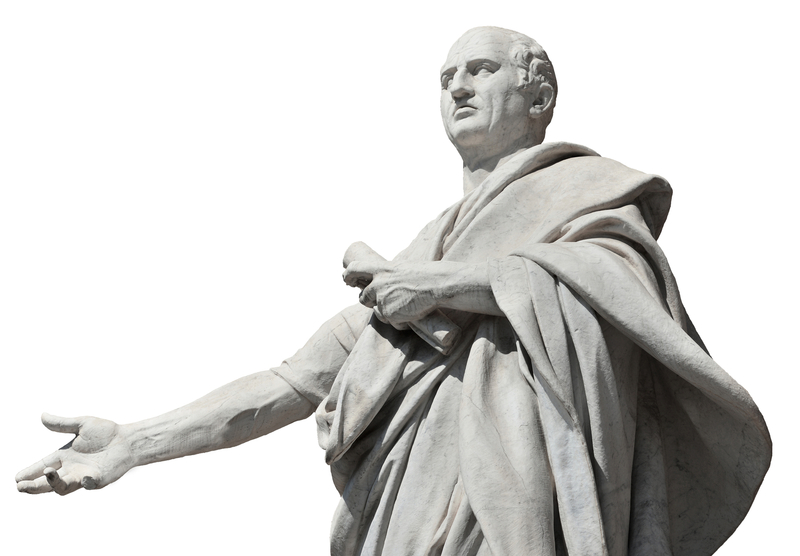

In [18]:
# Extract title, date, content paragraphs and link
title   = soup.find('h1').get_text(strip=True)
date    = soup.find('time')['datetime']
link    = soup.find('a')['href']
content = [p.get_text(strip=True) for p in soup.find_all('p')]
content = ' '.join(content)
pprint({'title': title, 'date': date, 'link': link, 'content': content[:250]}, sort_dicts=False)

# Extracts list elements, table and image
elems = [li.get_text(strip=True) for li in soup.find('ul').find_all('li')]
table = pd.read_html(io.StringIO(html))[0]
image = soup.find('img').get('src')
image = Image.open(io.BytesIO(requests.get(image).content))
print('List:\n',  elems)
print('Table:\n', table)
display(image)

**4. Inspect a webpage**

Select an article from the [BBC News website](https://www.bbc.com/news). Open your browser's inspector by right-clicking on the page and choosing `Inspect` to examine the page structure (Firefox, Chrome) in the Inspector tool (ignore the other tools for now). You can click an element on the page to highlight it in the inspector using `Inspect`, or select an element in the inspector and `Scroll Into View`.

Note: In Safari, you must enable `Show features for web developers` under `Safari > Settings > Advanced` before you can use `Inspect Element`.

![Inspector](https://www.dropbox.com/scl/fi/sd8b2d7kn4d7ku99j29iu/fig_inspector.jpg?rlkey=4zklhe56g4hoys09yvr2c90tb&dl=1)

**5. Scrape a webpage** 

Copy the article URL, download the raw HTML with `requests.get`, and parse into a document tree using `bs4`. Extract the article's title, date, and content paragraphs as in the earlier examples. Optionally, wrap these steps in a function that takes a URL as input and returns the extracted elements.

Note: I recommend using HTML selectors to target elements in the document tree, as in the earlier examples. You may also use CSS selectors, which can be copied from your browser's inspector via `Right-click > Copy > CSS Selector`. Avoid absolute CSS paths or XPaths that rely on node positions in the tree, as they break whenever the page structure changes.

Note: `requests.get` returns an HTTP status code: `200` means the request succeeded, `400` means the request was malformed, `404` means the requested resource was not found, and `429` means the client has sent too many requests and has been rate-limited. Refer to [this website](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Status) for a comprehensive list response status codes.

In [19]:
url  = 'https://www.bbc.com/news/articles/cwy170jkekdo'
html = requests.get(url)
print('Status code:', html.status_code)

soup = bs4.BeautifulSoup(html.text, 'html.parser')

# Selectors
title = soup.find('h1').get_text() # HTML selector
title = soup.select_one('.sc-f98b1ad2-0').get_text() # CSS selector
title = soup.select_one('html body div#__next div.app main#main-content article div.sc-3b6b161a-0.hNbOGD h1.sc-f98b1ad2-0.idLnWK').get_text() # CSS path

Status code: 200


In [20]:
def get_article_data(html:str) -> dict:
    soup    = bs4.BeautifulSoup(html.text, 'html.parser')
    title   = soup.find('h1').get_text()
    date    = soup.find('time').get('datetime')
    date    = datetime.datetime.strptime(date, '%Y-%m-%dT%H:%M:%S.%fZ').replace(tzinfo=datetime.timezone.utc)
    date    = date.date()
    content = soup.find_all('div', attrs={'data-component': 'text-block'})
    content = [p for div in content for p in div.find_all('p')]
    content = [p.get_text(strip=True) for p in content]
    content = '\n'.join(content)
    return {'title':title, 'date':date, 'content':content}

response = requests.get(url)
article  = get_article_data(response)
pprint(article)

{'content': "Ukraine will receive up to 100 of France's Rafale F4 fighter jets "
            'as well as advanced air defence systems in a major deal to boost '
            "Kyiv's ability to protect itself against deadly Russian attacks.\n"
            'Ukrainian President Volodymyr Zelensky hailed the move as '
            '"historic", after signing the letter of intent with his French '
            'counterpart Emmanuel Macron at an air base near Paris.\n'
            'Deliveries of the Rafale F4s are planned to be completed by 2035, '
            'while the joint production of interceptor drones is starting this '
            'year.\n'
            'Financial details are yet to be worked out, but reports say '
            'France plans to attract EU financing and also accessfrozen '
            'Russian assets - a controversial move that has split the '
            '27-member bloc.\n'
            '"This is a strategic agreement which will last for 10 years '
            'starting fr

**6. Application Programming Interface (answer provided)** 

An API (Application Programming Interface) is a standardised interface that allows one program to request data or services from another.

The [GDELT project](https://www.gdeltproject.org/) (Global Database of Events, Language, and Tone) produces an automated real-time global news database, and provides an API that enables systematic retrieval and analysis of media content. The GDELT API provides metadata such as title, date and URL but not the full article, which needs to be collected separately. The query keywords are matched against both the article title and the article content.

An API call is a URL that tells a server what data you want. It contains:

- A server endpoint e.g. `https://api.gdeltproject.org/api/v2/doc/doc`
- A query e.g. `ukraine` preceded by `?query=`
- Arguments e.g. `format=json` separated by `&`

The API is an URL formatted as `<server>?query=<query>&<arg1>&<arg2><...>`, where the query and parameters must be [URL-encoded](https://developer.mozilla.org/en-US/docs/Glossary/Percent-encoding). The structure of queries and parameters is specific to each API, so consult the [GDELT API documentation](https://blog.gdeltproject.org/gdelt-doc-2-0-api-debuts/) for the correct syntax.

Note: GDELT, like many other websites, rate-limits or blocks automated requests i.e. HTTP `429` errors. For repeated queries to the same server, a request header is usually required. This header carry metadata about a web request, and the `User-Agent` header in particular identifies the browser and operating system, helping automated requests resemble those sent by a real browser. You can check your browser's HTTP header in the inspector tool or [here](https://httpbin.org/headers). Besides, requests should include a random, realistic, delay (e.g. 1.5–3 seconds) between calls.

In [ ]:
# Server, query and parameters
server = 'https://api.gdeltproject.org/api/v2/doc/doc'
params = {
    'query': 'domain:bbc.com AND sourcelang:english AND ukraine AND war',
    'mode': 'artlist',
    'format': 'json'
}

# Minimal headers
headers = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7)'
}

# Collects articles in 5-day intervals
start    = datetime.datetime(2025,  11, 30)
end      = datetime.datetime(2025,  12, 31)
step     = datetime.timedelta(days=5)
current  = start
articles = list()

while current <= end:
    params.update({
        'startdatetime': current.strftime('%Y%m%d%H%M%S'),
        'enddatetime':   min(current + step - datetime.timedelta(seconds=1), end).strftime('%Y%m%d%H%M%S')
    })
    print(f"From {params['startdatetime']} to {params['enddatetime']}...")
    # Make request
    response = requests.get(server, params=params, headers=headers)
    if response.status_code == 200:
        data = response.json()
        if data:
            articles.append(pd.DataFrame(data['articles']))
    else:
        print(f'HTTP error {response.status_code}')
    time.sleep(random.uniform(1.5, 3.0))
    current += step

# Formats articles
articles = pd.concat(articles, ignore_index=True)
articles = articles.drop(columns=['url_mobile']).set_index('url')
articles = articles.assign(date=pd.to_datetime(articles['seendate']).dt.date).drop(columns=['seendate'])
articles = articles[['title', 'domain', 'date', 'sourcecountry', 'language', 'socialimage']]
articles = articles.sort_values(by='date')

**7. Scrape at scale**

Use a loop to fetch the content of each article URL. Make sure to set appropriate headers, check the HTTP response status code, and include a random delay between requests. Store the retrieved article text as an additional column in the resulting `pd.DataFrame`. 

Note: For large-scale data collection, it is usually a good idea to wrap your web-scrapping code in a try-except block to handle failed requests gracefully and prevent the loop from terminating when an error occurs. The except statement can be used to catch specific exceptions.

```{python}
try:
    ...
except Exception as e:
    print(e)
```

In [ ]:
def get_article_content(response:str) -> str:
    soup    = bs4.BeautifulSoup(response.text, 'html.parser')
    content = soup.find_all('div', attrs={'data-component': 'text-block'})
    content = [p for div in content for p in div.find_all('p')]
    content = [p.get_text(strip=True) for p in content]
    content = '\n'.join(content)
    return content

contents = dict()

for url in tqdm(articles.index):
    try:
        response = requests.get(url, headers=headers, timeout=10)
        if response.status_code == 200:
            content = get_article_content(url, headers)
            if content:
                contents[url] = content
        else:
            print(f'HTTP {response.status_code} for {url}')
    except requests.exceptions.RequestException as e:
        print(f'Request failed for {url}: {e}')
    time.sleep(random.uniform(0.5, 1.0))   

articles = articles.join(pd.Series(contents, name='content'))
articles = articles.dropna(subset=['content'])

**8. Pre-processing**

For the remainder of this tutorial, use the provided `articles.csv` dataset containing more than 2800 articles from BBC news since the start of the conflict.

Pre-processing usually involves the following steps:
- **Lowercasing** converts all text to lowercase to ensure consistency and avoid treating the same word with different capitalisations as distinct tokens.
- **Tokenising** is the process of breaking text into smaller units (tokens), such as words, symbols, or phrases, to make it easier to analyse. E.g. `the ukraine war` → `['the', 'ukraine', 'war']`
- **Removing special characters** including punctuation, symbols, quotes that carry little semantic information, in order to reduce dimensionality. A good option is to preserve only alphanumeric tokens.
- **Removing stop words** such as `a`, `the` or `and` that carry little semantic information, in order to reduce dimensionality.
- **Lemmatising** or reducing tokens to their canonical or dictionary form or lemma, based on linguistic rules and context. E.g. `running` → `run` ; `ran` → `run`. Alternatively **stemming** reduces tokens to their root form using heuristic rules, without guaranteeing that the result is a valid word.

For each article, convert the text to lowercase, tokenise it using `nltk.tokenize.word_tokenize`, retain only alphanumeric tokens, remove stopwords from `nltk.corpus.stopwords.words('english')`, and lemmatise using `nltk.stem.WordNetLemmatizer()`.

In [21]:
def tokenise(string:str, stopwords:list=None, lemmatiser=None) -> str:
    tokens = string.lower()
    tokens = nltk.tokenize.word_tokenize(tokens)
    tokens = [token for token in tokens if token.isalnum()]
    if stopwords:
        tokens = [token for token in tokens if token not in stopwords]
    if lemmatiser:
        tokens = [lemmatiser.lemmatize(token) for token in tokens]
    return tokens

stopwords  = nltk.corpus.stopwords.words('english')
lemmatiser = nltk.stem.WordNetLemmatizer()

articles = pd.read_csv('articles.csv', index_col='url')
articles['word_tokens'] = articles['content'].progress_apply(
    lambda x: tokenise(string=x, stopwords=stopwords, lemmatiser=lemmatiser))

100%|██████████| 2872/2872 [00:09<00:00, 302.58it/s]


**9. N-grams**

Generate a word cloud using `wordcloud.WordCloud` to visualise the most frequent terms. Use `nltk.FreqDist` and `ngrams` to compute the most common unigrams (single tokens) and plot a bar chart of their frequencies. Repeat the analysis for bigrams and trigrams. Optionally, restrict the analysis to the 10 000 most frequent unigrams.

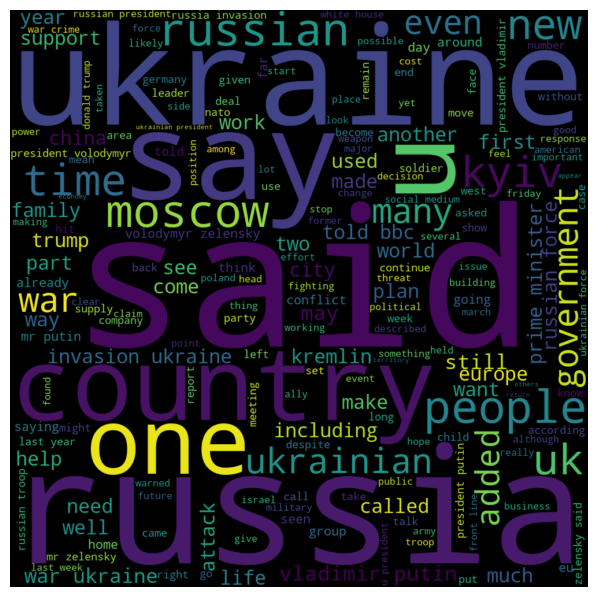

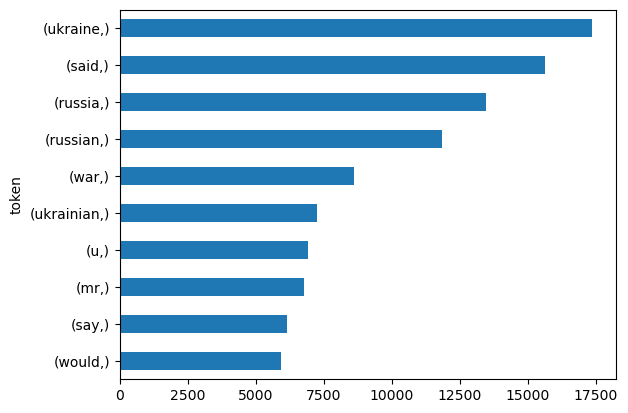

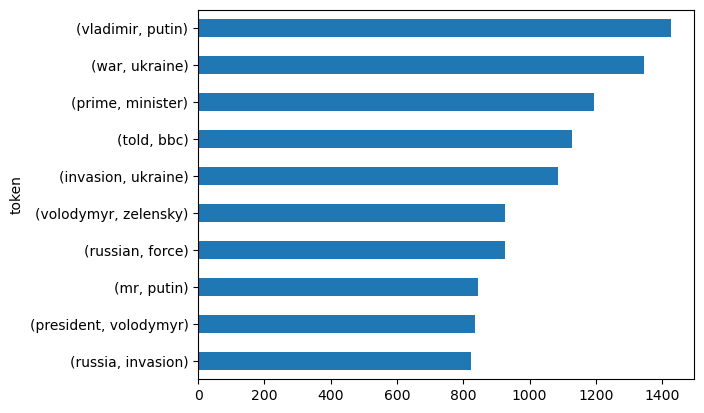

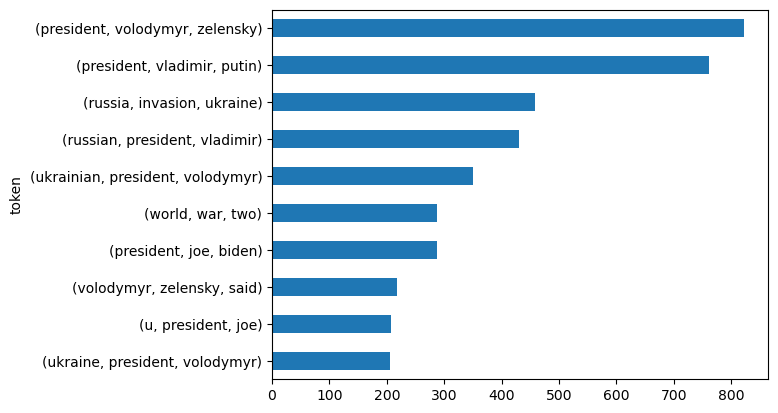

In [22]:
# Word cloud
figdata = ' '.join(articles['word_tokens'].apply(lambda x: ' '.join(x)).tolist())
figdata = wordcloud.WordCloud(width=1000, height=1000, background_color='black').generate(figdata)
plt.figure(figsize=(7.5,7.5))
plt.imshow(figdata, interpolation='bilinear')
plt.axis('off')
plt.show()
plt.close()

# N-gram frequency
for n in [1, 2, 3]:
    ngrams_freq = nltk.FreqDist()
    for tokens in articles['word_tokens']:
        ngrams_freq.update(ngrams(tokens, n))
    figdata = pd.DataFrame(ngrams_freq.most_common(10), columns=['token', 'count']).sort_values(by='count', ascending=True)
    figdata.plot.barh(x='token', y='count', legend=False)

# Filter each article
most_common = nltk.FreqDist(token for document in articles['word_tokens'] for token in document)
most_common = {token for token, _ in most_common.most_common(10_000)}
articles['word_tokens'] = articles['word_tokens'].apply(
    lambda tokens: [token for token in tokens if token in most_common]
)

**10. Sentiment analysis**

VADER (Valence Aware Dictionary and sEntiment Reasoner) is a lexicon- and rule-based sentiment analysis system that uses a predefined sentiment lexicon in which words are assigned positive, negative, or neutral scores. 

- Compute sentence token for each article and compute the polarity scores using `sentiment.SentimentIntensityAnalyzer`, which implements VADER.
- Classify each sentence as being about Russia, Ukraine, or other based on keywords and a threshold.
- Plot the evolution of the average compound score over the course of the conflict, optionally applying a rolling window to smooth short-term fluctuations.

100%|██████████| 2872/2872 [00:09<00:00, 310.72it/s]


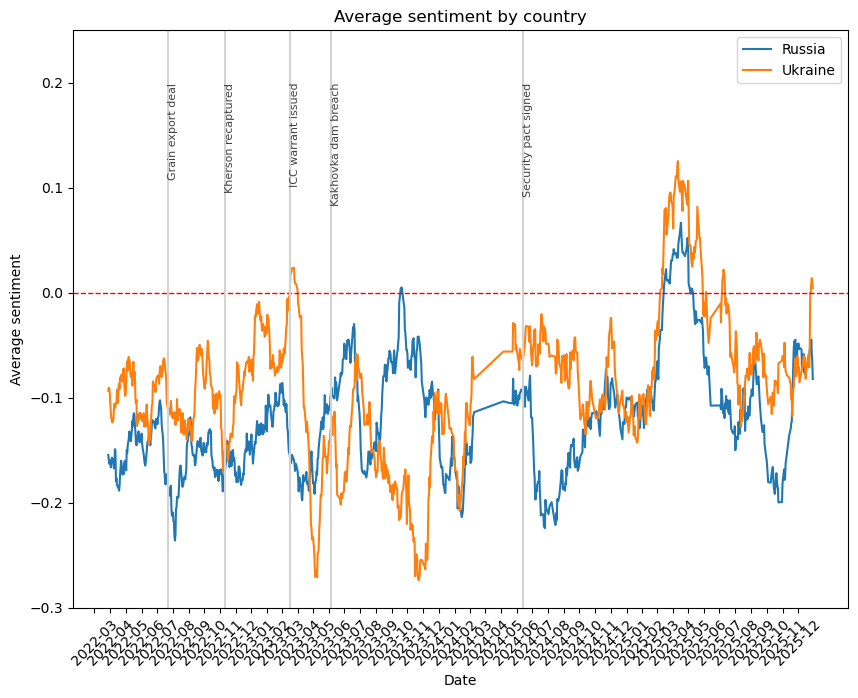

In [23]:
# Compute sentiment per sentence
analyser = sentiment.SentimentIntensityAnalyzer()
articles['sentence_token'] = articles['content'].apply(lambda text: nltk.tokenize.sent_tokenize(text))
articles['sentiments']     = articles['sentence_token'].progress_apply(lambda sentences: [analyser.polarity_scores(sentence)['compound'] for sentence in sentences])

# Sentence classification by keywords
def classify_sentence(sentence:str, keywords:dict, threshold:float=0.75) -> str:
    sentence = sentence.lower()
    scores   = {key:sum(word in sentence for word in value) for key, value in keywords.items()}
    if sum(scores.values()) > 0:
        scores = {key:value / sum(scores.values()) for key, value in scores.items()}
    label = max(scores, key=scores.get) if max(scores.values()) > threshold else 'other'
    return label

keywords = {
    'russia':   ['russia', 'russian', 'moscow', 'kremlin', 'putin'],
    'ukraine':  ['ukraine', 'ukrainian', 'kyiv', 'zelensky']
}

articles['labels'] = articles['sentence_token'].apply(lambda x: [classify_sentence(sentence, keywords) for sentence in x])

# Formats sentiment data
sentiments = articles[['date', 'labels', 'sentiments']]
sentiments = sentiments.explode(column=['labels', 'sentiments'])
sentiments = sentiments.groupby(['date', 'labels'])['sentiments'].mean().unstack(fill_value=0)
sentiments = sentiments.rolling(window=30, min_periods=30).mean()
sentiments = sentiments.dropna(how='all')
sentiments.index = pd.to_datetime(sentiments.index)

# Events
events = pd.Series({
    '2022-07-22': 'Grain export deal',
    '2022-11-11': 'Kherson recaptured',
    '2023-03-17': 'ICC warrant issued',
    '2023-06-06': 'Kakhovka dam breach',
    '2024-06-13': 'Security pact signed'
})
events.index = pd.to_datetime(events.index)

# Figure
plt.figure(figsize=(10,7.5))
for label in ['russia', 'ukraine']:
    plt.plot(sentiments.index, sentiments[label], label=label.title())
plt.axhline(y=0, linestyle='--', linewidth=1, color='red')
for date, label in events.items():
    plt.axvline(date, color='lightgrey')
    plt.text(date, 0.2, label, va='top', rotation=90, fontsize=8, alpha=0.75, clip_on=True)
xticks = pd.date_range(sentiments.index.min().to_period('M').to_timestamp(), sentiments.index.max().to_period('M').to_timestamp(), freq='MS')
plt.xticks(xticks, xticks.strftime('%Y-%m'), rotation=45)
plt.xlabel('Date')
plt.ylabel('Average sentiment')
plt.ylim(-0.3, 0.25)
plt.title('Average sentiment by country')
plt.legend()
plt.show()

**Bonus (intermediate): Headless browser**

Use Selenium to automate a browser and collect HTML from a dynamic website. Open the BBC homepage, interact with the page using XPath (sign in and navigate to News), scroll to load additional content, then extract the rendered HTML and parse it with BeautifulSoup. This exercise illustrates how browser automation is needed to scrape JavaScript-driven pages.

In [ ]:
import bs4
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.support.ui import WebDriverWait

options = webdriver.firefox.options.Options()
service = webdriver.firefox.service.Service(executable_path='/opt/homebrew/bin/geckodriver')
driver  = webdriver.Firefox(service=service, options=options)
driver.get('https://www.bbc.com')
driver.find_element(By.XPATH, "//button[.//span[text()='Sign In']]").click()
driver.find_element(By.XPATH, "//input[@id='username']").send_keys("Login") # Add login here
driver.find_element(By.XPATH, "//button[@id='submit-button']").click()
driver.find_element(By.XPATH, "//input[@id='password']").send_keys("Password") # Add password here
driver.find_element(By.XPATH, "//button[@id='submit-button']").click()
driver.find_element(By.XPATH, "//a[normalize-space()='News']").click()
for _ in range(50):           # number of steps
    driver.execute_script("window.scrollBy(0, 50);")  # 50 px per step
    time.sleep(0.05) 
html = driver.page_source
soup = bs4.BeautifulSoup(html, 'html.parser')
driver.quit()

**Bonus (advanced): Regular expressions**

Regular expressions (regex) are rule-based patterns for matching and manipulating text. In text modelling, they are extremely useful for cleaning and standardising text, reducing noise, and preparing data for tokenisation and further analysis.

Learn regular expressions basics using the [RegexOne website](https://regexone.com/).